In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

#### Résolution du modèle de Variation Totale L2 par ISTA

### 1. Modèle variationnel et objectif du débruitage

On observe une image bruitée $f=u_{\mathrm{vrai}}+\varepsilon$ et on cherche une image reconstruite $u$ qui reste proche des données tout en étant régulière. Le modèle de Rudin–Osher–Fatemi (ROF) s'écrit

$$
\min_u \; P(u)=\frac12\|u-f\|_2^2+\lambda\,\operatorname{TV}(u),\qquad \lambda>0.
$$

Le premier terme est une **fidélité aux données de type $L^2$** ; le second pénalise les variations spatiales. Le paramètre $\lambda$ règle le compromis entre conservation des détails et lissage.

À partir du gradient discret $Du=(D_1u,D_2u)$, on distingue deux définitions :

$$
\operatorname{TV}_{\mathrm{aniso}}(u)=\sum_{i,j}\bigl(|(D_1u)_{ij}|+|(D_2u)_{ij}|\bigr),
\qquad
\operatorname{TV}_{\mathrm{iso}}(u)=\sum_{i,j}\sqrt{(D_1u)_{ij}^2+(D_2u)_{ij}^2}.
$$

Dans `TotalVariation`, `p=1` calcule la **TV anisotropique**, tandis que `p=2` calcule la **TV isotropique**. Le terme « $L^2$ » peut donc désigner la fidélité quadratique, sans nécessairement désigner la norme choisie dans la TV.

In [3]:
#Total variation operator
def TotalVariation(u, p=1):
    #u:matrice de n lines et m colonnes
    # p=1 anisotropique et p=2  isotropique
    M = D(u)
    if(p==1):
        return np.sum(np.abs(M[0]) + np.abs(M[1]))
    else:
        return np.sum((np.abs(M[0])**p + np.abs(M[1])**p)**(1/p))

In [4]:
#gradient discret
def D(u):
    # u:matrice à n lines et m colonnes
    n = np.shape(u)[0]
    m = np.shape(u)[1]
    #Matrice différences sur les lignes
    L = np.zeros((n,m))
    for i in range(n-1):
        L[i] = u[i+1] - u[i]
    #Matrice différences sur les colonnes
    C = np.zeros((n,m))
    for j in range(m-1):
        C[:,j] = u[:,j+1] - u[:,j]

    return np.array([L,C])

In [5]:
def D_dual(u):
    # u:matrice de taille mxnx2
    v = u[0]
    m = np.shape(v)[0]
    n = np.shape(v)[1]
    #Matrice L = Gradient^T x u
    L = np.zeros(np.shape(v))
    L[0] = -v[0]
    L[m-1] = v[m-2]
    for i in range(1,m-1):
        L[i] = v[i-1] - v[i]
    v = u[1]
    #Matrice C
    C = np.zeros(np.shape(v))
    C[:,0] = -v[:,0]
    C[:,n-1] = v[:,n-2]
    for j in range(1,n-1):
        C[:,j] = v[:,j-1] - v[:,j]
        
    return L+C

### 2. Gradient discret et adjoint

La fonction `D` calcule des différences finies vers l'avant dans les deux directions de l'image. La fonction `D_dual` implémente l'**adjoint** $D^*$ du gradient discret, avec les conventions de bord présentes dans le code :

$$
\langle Du,p\rangle=\langle u,D^*p\rangle.
$$

Cet opérateur est essentiel pour passer du problème en image $u$ à un problème en champ dual $p=(p_1,p_2)$. Il est parfois décrit comme l'opposé d'une divergence discrète ; le signe dépend des conventions retenues.

In [6]:
def proj_L2(v, sigma):
    if(np.linalg.norm(v) <= sigma):
        return v
    else:
        return sigma*(v/np.linalg.norm(v))
def prox_F_etoile(y, sigma):
    #y matrice de taille mxnx2
    X = y[0] #coordonnées en x
    Y = y[1] #coordonnées en y
    for i in range(np.shape(X)[0]):
        for j in range(np.shape(X)[1]):
            v = np.array([X[i][j], Y[i][j]])
            v = proj_L2(v, sigma)
            X[i][j] = v[0]
            Y[i][j] = v[1]
    return [X,Y]

In [7]:
def prox_G(u_tilde, u_etoile, tau):
    return (u_tilde + tau*u_etoile)/(1+tau)

### 3. Projection duale : pourquoi une boule $\ell_2$ 

Pour la **TV isotropique**, on utilise l'identité

$$
\operatorname{TV}_{\mathrm{iso}}(u)
=\max_{p\in\mathcal C}\langle Du,p\rangle,
\qquad
\mathcal C=\bigl\{p:\|p_{ij}\|_2\le1\ \text{pour tout pixel }(i,j)\bigr\}.
$$

Chaque vecteur $p_{ij}=((p_1)_{ij},(p_2)_{ij})$ appartient donc au disque unité. La fonction `proj_L2` calcule sa projection euclidienne :

$$
\Pi_{B_2(0,1)}(v)=\frac{v}{\max(1,\|v\|_2)}.
$$

`prox_F_etoile` applique cette projection **pixel par pixel** aux deux composantes du champ dual. Cette étape impose la contrainte $\|p_{ij}\|_2\le1$ après chaque mise à jour.



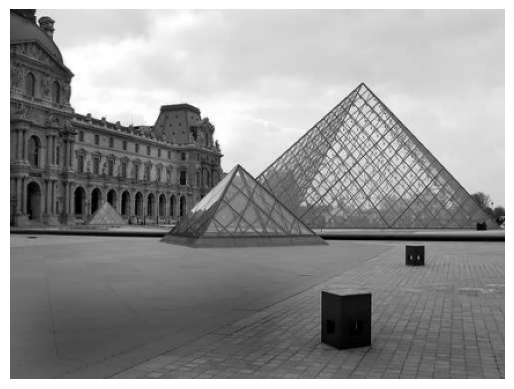

In [8]:
#image à débruiter
img = cv2.imread("img.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)/255
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

In [9]:
def Bruit(u, sigma=0.25, moy=0):
    #u image qu'on souhaite bruitée
    #sigma écart_type
    #moy moyenne
    m = np.shape(u)[0]
    n = np.shape(u)[1]
    return np.random.normal(moy, sigma, size=(m,n))

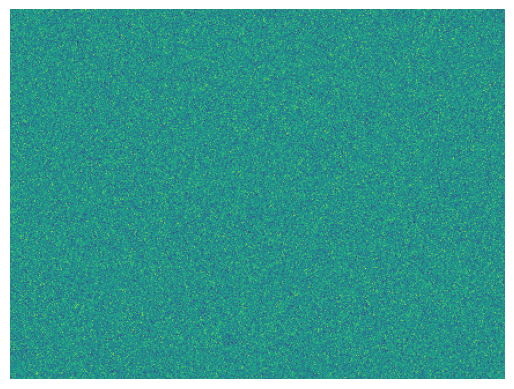


[[-0.12591879  0.17924517 -0.29018007 ... -0.22511566 -0.29229031
   0.28156875]
 [-0.04667391 -0.03439451  0.04975198 ... -0.4514542  -0.19129211
  -0.03727998]
 [ 0.15499817 -0.09631373 -0.06405583 ... -0.29904734  0.35561605
   0.01599768]
 ...
 [-0.02852186 -0.12585678  0.32463064 ...  0.12546486 -0.14387577
  -0.14705795]
 [-0.276667   -0.41649466  0.22876147 ... -0.06513248  0.45750357
   0.22785147]
 [ 0.07405151 -0.29896649  0.53335441 ... -0.35290505 -0.09238917
  -0.08152356]]


In [10]:
#Image du bruit
e = Bruit(img)
plt.imshow(e)
plt.axis('off')  
plt.show()
print()
print(e)

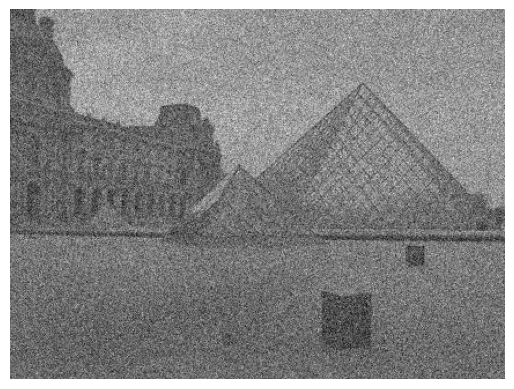

In [11]:
#image plus le bruit
plt.imshow(img + e,  cmap='gray')
plt.axis('off') 
plt.show()
img = img+e

### 4. Construction de l'image bruitée

On charge une image en niveaux de gris, puis on lui ajoute un bruit gaussien $\varepsilon_{ij}\sim\mathcal N(0,\sigma^2)$, indépendamment sur chaque pixel. Dans la suite, `img` désigne donc **l'observation bruitée** $f$, et non plus l'image originale.

In [12]:
def Objectif_Dual(x, lamb):
    return 0.5*np.linalg.norm(img - lamb*D_dual(x))**2

In [13]:
def Objectif_primale(x, lamb):
    return 0.5*np.linalg.norm(img-x)**2+lamb*TotalVariation(x,1)

### 5. Formulation duale et itération de type ISTA

Dans le cas **isotropique** associé à la projection sur les boules $\ell_2$, la dualisation conduit à minimiser

$$
\min_{p\in\mathcal C}\; Q(p)=\frac12\|f-\lambda D^*p\|_2^2,
\qquad \mathcal C=\{p:\|p_{ij}\|_2\le1\}.
$$

Le gradient de la partie lisse est

$$
\nabla Q(p)=\lambda^2 DD^*p-\lambda Df.
$$

On reconnaît un problème composite $Q(p)+\iota_{\mathcal C}(p)$, où $\iota_{\mathcal C}$ vaut $0$ sur $\mathcal C$ et $+\infty$ ailleurs. Le proximal de cette indicatrice est simplement la projection sur $\mathcal C$. Une **itération ISTA / gradient projeté sur le dual** s'écrit donc

$$
\boxed{\ p^{k+1}=\Pi_{\mathcal C}\left(p^k-\alpha\left[\lambda^2 DD^*p^k-\lambda Df\right]\right).\ }
$$

Si $L=\lambda^2\|D\|^2$ est une constante de Lipschitz du gradient, un choix classique est $\alpha\le 1/L$. Avec les différences finies 2D usuelles, $\|D\|^2\le8$ : le code choisit `alpha = 1/(lamb*8)`, qui est conservateur pour $\lambda=0.15$ et vérifie alors $\alpha\le 1/(8\lambda^2)$.

Après mise à jour du dual, l'image reconstruite est donnée par

$$
\boxed{\ u^k=f-\lambda D^*p^k.\ }
$$

Les tableaux `Obj_dual` et `Obj_primale` enregistrent les quantités calculées à chaque itération. **Précision :** `Objectif_Dual` est la fonction quadratique $Q$ **minimisée** (pas la valeur du dual concave à maximiser). Et, du fait de la différence isotropique/anisotropique mentionnée plus haut, `Obj_primale` ne mesure pas exactement le primal associé à la projection utilisée.

In [ ]:
#ISTA Débruitage


lamb = 0.15
alpha = 1/(lamb**2*8)
x_k = np.array([img, img])
it = 100
Obj_dual = np.array([Objectif_Dual(x_k, lamb)])
Obj_primale =  np.array([Objectif_primale(img -  lamb*D_dual(x_k), lamb)])
for k in range(it):
    x_k = prox_F_etoile(x_k - alpha*(lamb**2*D(D_dual(x_k))-lamb*D(img)), sigma=1)
    Obj_dual = np.append(Obj_dual, Objectif_Dual(x_k, lamb))
    u = img - lamb*D_dual(x_k)


u = img - lamb*D_dual(x_k)

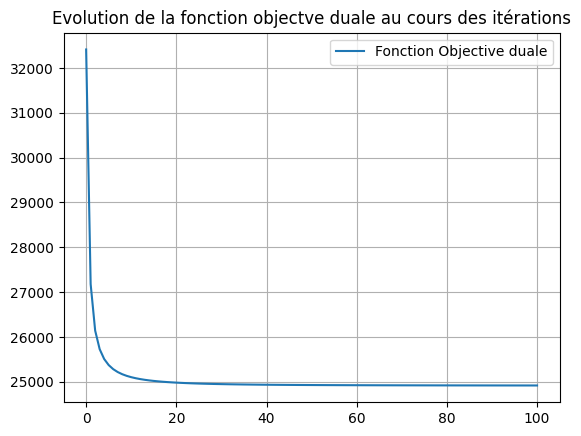

In [26]:
plt.plot(Obj_dual, label="Fonction Objective duale")
plt.title("Evolution de la fonction objectve duale au cours des itérations")
plt.grid()
plt.legend()
plt.show()

(np.float64(-0.5), np.float64(427.5), np.float64(319.5), np.float64(-0.5))

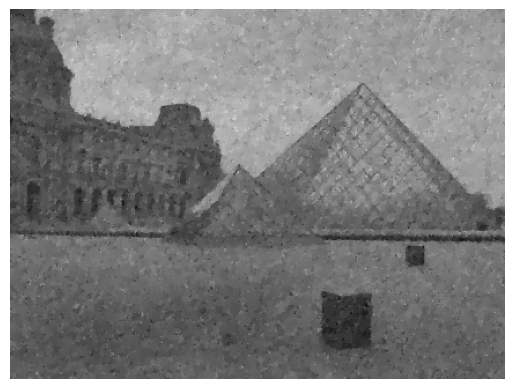

In [16]:
plt.imshow(u, cmap='gray')
plt.axis('off')

### 6. Lecture des résultats

Le premier graphique permet de suivre l'évolution numérique des quantités enregistrées pendant les 100 itérations. La fonction duale quadratique $Q(p^k)$ est l'objectif optimisé par le gradient projeté ; la valeur primale affichée sert ici d'indicateur de l'évolution de l'image reconstruite.

#### Résolution du problème d'optimisation LASSO par FISTA et ISTA

On s'intéresse au problème LASSO (*Least Absolute Shrinkage and Selection Operator*),
qui correspond au problème des moindres carrés avec régularisation $\ell_1$ :
$$\min_{x \in \R^n} \frac{1}{2} \| Ax - y \|_2^2  + \lambda \| x\|_1.$$
Ce problème est de la forme
$$\min_{x \in \R^n} f(x) + g(x)$$
avec 
- $f(x) = \frac{1}{2} \| Ax - y \|_2^2$ convexe et différentiable à gradient $L$-Lipschitz,
- $g(x) = \lambda \|x \|_1$ convexe, s.c.i. et propre.

### Algorithme Forward-Backward (ISTA)

On rappelle l'algorithme Forward-Backward pour un problème de la forme précédente :
- $\gamma \in ]0, \frac{2}{L}[$, $x_0 \in \R^n$
- pour $k \ge 0$, $x_{k+1} = \operatorname{prox}_{\gamma g}(x_k - \gamma \nabla f(x_k))$

Alors $(x_k)_k$ convergent vers une solution (s'il en existe une, ce qui est le cas pour LASSO).

### Algorithme Forward-Backward accéléré (FISTA)

Il existe l'accélération suivante due à Beck et Teboulle en 2009 de l'algorithme précédent :

- $\gamma \in ]0, \frac{1}{L}]$, $\tilde x_0 = x_0 \in \R^n$, $t_0=1$
- pour $k \ge 0$, 
$ \begin{cases}
x_{k+1} = \operatorname{prox}_{\gamma g}(\tilde x_k - \gamma \nabla f(\tilde x_k)) \\
t_{k+1} = \frac{1+\sqrt{4t_k^2+1}}{2} \\
\tilde x_{k+1} = x_{k+1} + \frac{t_k-1}{t_{k+1}}(x_{k+1}-x_k)
\end{cases}$

In [17]:
n = 500
s = 10
m = int(np.ceil(s * np.log(n)))
sigma = 1e-2
np.random.seed(1) 
A = np.random.randn(m,n)
x = np.zeros(n)
I = np.random.permutation(n)
x[I[0:s]] = np.random.randn(s)
x_true = x / np.linalg.norm(x)
v = sigma*np.random.randn(m)
y = A @ x_true + v

On fixe pour ce modèle $\lambda = 1$ (dans LASSO) et le pas $\gamma = \frac{1}{L}$ (pour ISTA et FISTA)

In [18]:
def f(x):
    return (1/2)*np.linalg.norm(A@x-y, ord=2)**2

In [19]:
def g(x):
    return lamb*np.linalg.norm(x, ord=1)

In [20]:
def F(x):
    return g(x) + f(x)

In [21]:
def prox_g(x , gamma, lamb):
    return np.sign(x)*np.maximum(np.abs(x)-gamma*lamb,0)

In [22]:
def grad_f(x):
    return A.T@(A@x-y)

##### Résolution du problème par ISTA

In [23]:
%%time
it = 1000
x_k = np.zeros(n)
gamma = 1/np.linalg.norm(A, ord=2)**2 #On prend gamma = 1/L
F_ISTA = np.array([F(x_k)])
lamb = 1
for k in range(1,it+1):
    x_k = prox_g(x_k - gamma*grad_f(x_k), gamma, lamb)
    F_ISTA = np.append(F_ISTA, F(x_k))

CPU times: total: 62.5 ms
Wall time: 67.4 ms


#### Résolution du problème par FISTA

In [24]:
%%time
it = 1000
x_k = np.zeros(n)
y_k = x_k.copy()
F_FISTA = np.array([F(x_k)])
t_k = 1

gamma = 1/np.linalg.norm(A, ord=2)**2
lamb = 1

for k in range(1, it+1):
    x = prox_g(y_k - gamma*grad_f(y_k), gamma, lamb)

    t = (1 + np.sqrt(1 + 4*t_k**2))/2

    y_k = x + ((t_k - 1)/t)*(x - x_k)

    x_k = x.copy()
    t_k = t

    F_FISTA = np.append(F_FISTA, F(x_k))

CPU times: total: 78.1 ms
Wall time: 80.5 ms


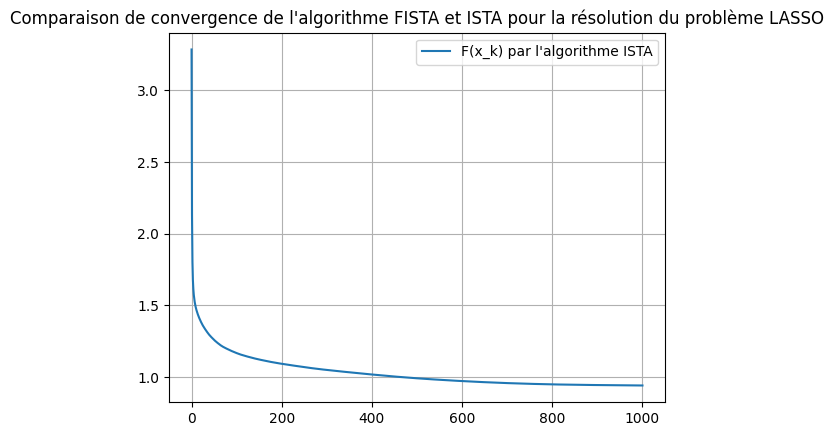

In [25]:
plt.plot(np.log(F_ISTA), label="F(x_k) par l'algorithme ISTA")
plt.grid()
plt.title("Comparaison de convergence de l'algorithme FISTA et ISTA pour la résolution du problème LASSO")
plt.legend()
plt.show()